In [35]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import classification_report,accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

In [36]:
data=pd.read_csv('Bank Customer Churn Prediction.csv')
data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [37]:
data.shape

(10000, 12)

C:\Users\mero1\AppData\Local\Temp\ipykernel_32520\365522152.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['credit_score'], color='green')
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


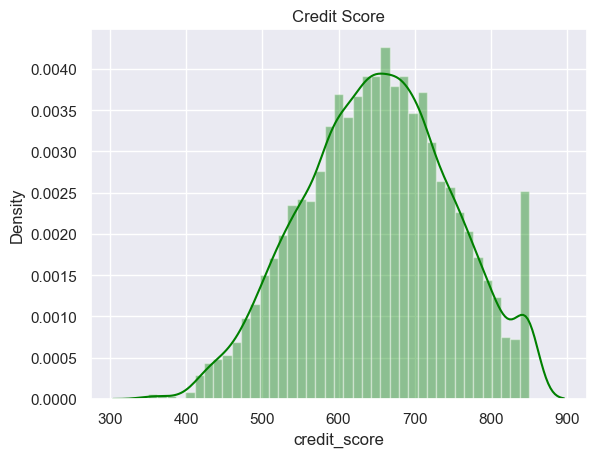

C:\Users\mero1\AppData\Local\Temp\ipykernel_32520\365522152.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['age'], color='red')
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


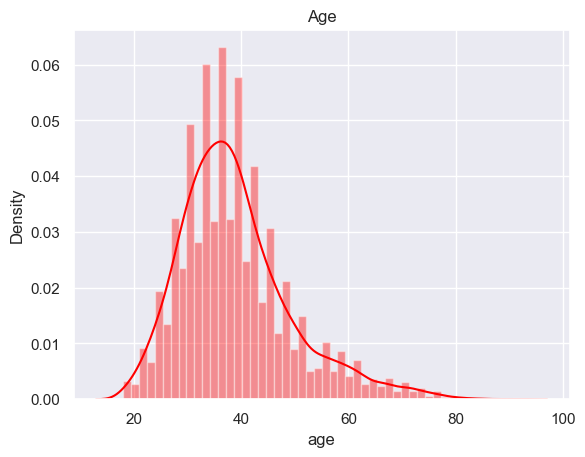

C:\Users\mero1\AppData\Local\Temp\ipykernel_32520\365522152.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['tenure'], color='blue')
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


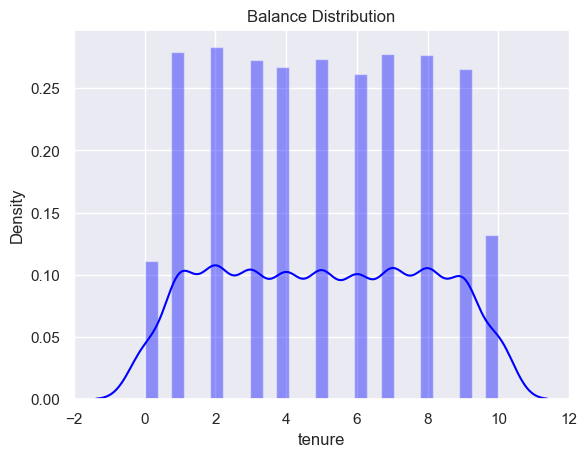

C:\Users\mero1\AppData\Local\Temp\ipykernel_32520\365522152.py:15: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['balance'], color='black')
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


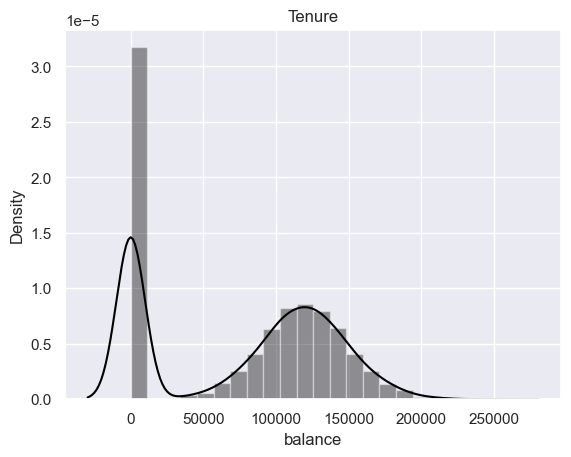

C:\Users\mero1\AppData\Local\Temp\ipykernel_32520\365522152.py:19: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['estimated_salary'], color='pink')
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


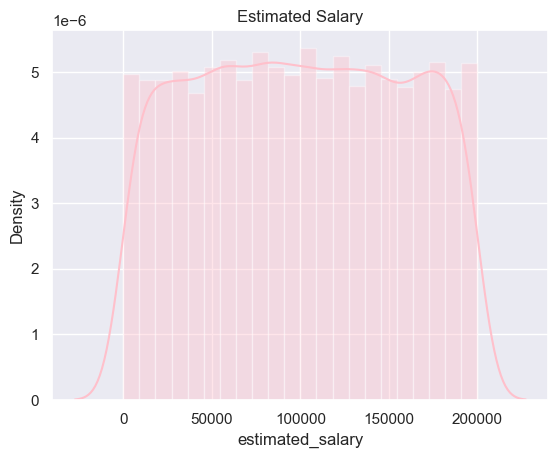

In [38]:
sns.set()

sns.distplot(data['credit_score'], color='green')
plt.title('Credit Score')
plt.show()

sns.distplot(data['age'], color='red')
plt.title('Age')
plt.show()

sns.distplot(data['tenure'], color='blue')
plt.title('Balance Distribution')
plt.show()

sns.distplot(data['balance'], color='black')
plt.title('Tenure')
plt.show()

sns.distplot(data['estimated_salary'], color='pink')
plt.title('Estimated Salary')
plt.show()

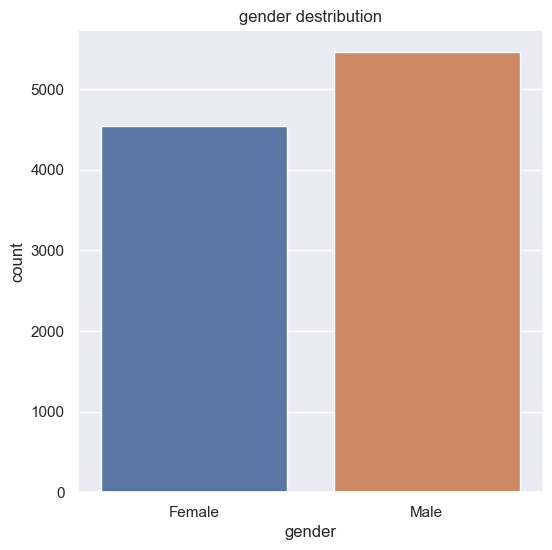

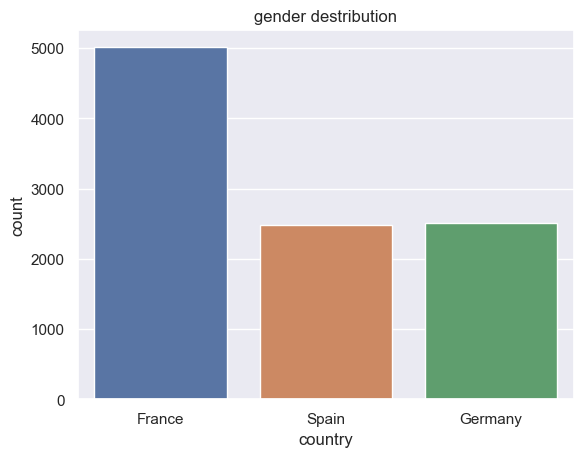

In [39]:
plt.figure(figsize=(6,6))

sns.countplot(x='gender', data=data)
plt.title('gender destribution')
plt.show()

sns.countplot(x='country', data=data)
plt.title('gender destribution')
plt.show()

In [40]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [41]:
data=data.drop(['customer_id'], axis=1)
data.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [42]:
x_train,x_test, y_train,y_test = train_test_split(data.drop(['churn' ], axis=1) ,data['churn'],test_size=0.2, random_state=42)

In [43]:
le = LabelEncoder()

x_train["gender"] = le.fit_transform(x_train["gender"])
x_test["gender"] = le.transform(x_test["gender"])

In [44]:
encoder = OneHotEncoder(drop='first', sparse=False)

train_countries = encoder.fit_transform(x_train[['country']])
test_countries = encoder.transform(x_test[['country']])

x_train = x_train.drop('country', axis=1)
x_test = x_test.drop('country', axis=1)

x_train[encoder.get_feature_names_out(['country'])] = train_countries
x_test[encoder.get_feature_names_out(['country'])] = test_countries

C:\anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [45]:
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

In [46]:
MMS = MinMaxScaler()

col_to_scale = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']

for col in col_to_scale:
    x_train_scaled[col] = MMS.fit_transform(x_train[[col]])
    x_test_scaled[col] = MMS.fit_transform(x_test[[col]])

x_train_scaled.head()

,credit_score,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_Germany,country_Spain
9254,0.672,1,0.189189,0.6,0.000000,2,1,1,0.895550,0.0,0.0
1561,0.564,1,0.324324,0.4,0.476786,2,1,1,0.980029,1.0,0.0
1670,0.418,1,0.081081,0.3,0.457317,1,1,0,0.429261,0.0,1.0
6087,0.422,0,0.121622,0.9,0.540606,1,1,0,0.765408,0.0,0.0
6669,0.334,1,0.513514,0.9,0.566554,1,0,0,0.197107,0.0,0.0


In [47]:
RF_model = RandomForestClassifier(random_state=42)
RF_model.fit(x_train, y_train)

y_pred_RF = RF_model.predict(x_test)

In [48]:
print("Random Forest Report:")
print(classification_report(y_test, y_pred_RF))

Random Forest Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1607
           1       0.77      0.46      0.57       393

    accuracy                           0.87      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.86      0.87      0.85      2000



In [49]:
def score( y_pred, y_true):
    print(f'Accuracy : {accuracy_score(y_test, y_pred)}')
    print(f'recall : {recall_score(y_true,y_pred)}')
    print(f'presecion : {precision_score(y_test, y_pred)}')
    print(f'F1Score : {f1_score(y_test, y_pred)}')
    print(f'Conf_Matrix :\n {confusion_matrix(y_test, y_pred)}')

score(y_test,y_pred_RF)
score

Accuracy : 1.0
recall : 0.7659574468085106
presecion : 1.0
F1Score : 1.0
Conf_Matrix :
 [[1607    0]
 [   0  393]]


<function __main__.score(y_pred, y_true)>

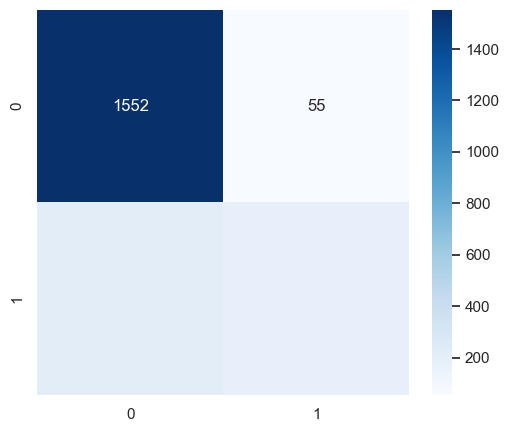

In [50]:
cm_RF=confusion_matrix(y_test, y_pred_RF)

plt.figure(figsize=(6,5))
sns.heatmap(cm_RF, cmap='Blues', annot=True, fmt="g")
plt.show()

In [51]:
XGB_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
XGB_model.fit(x_train, y_train)

y_pred_XGB = XGB_model.predict(x_test)

C:\anaconda\Lib\site-packages\xgboost\core.py:158: UserWarning: [21:51:54] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [52]:
print("XGBoost Report:")
print(classification_report(y_test, y_pred_XGB))

XGBoost Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      1607
           1       0.71      0.51      0.60       393

    accuracy                           0.86      2000
   macro avg       0.80      0.73      0.76      2000
weighted avg       0.85      0.86      0.86      2000



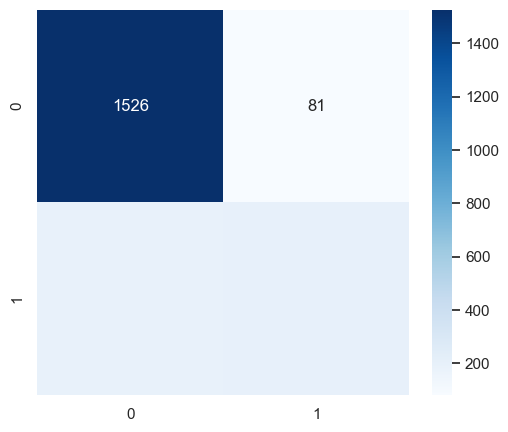

In [53]:
cm_XGB=confusion_matrix(y_test, y_pred_XGB)

plt.figure(figsize=(6,5))
sns.heatmap(cm_XGB, cmap='Blues', annot=True, fmt="g")
plt.show()

In [54]:
SVM_model = SVC(probability=True, random_state=42)
SVM_model.fit(x_train, y_train)

y_pred_SVM = SVM_model.predict(x_test)

In [55]:
print("SVM Report:")
print(classification_report(y_test, y_pred_SVM))

SVM Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1607
           1       0.00      0.00      0.00       393

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.80      0.72      2000



C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


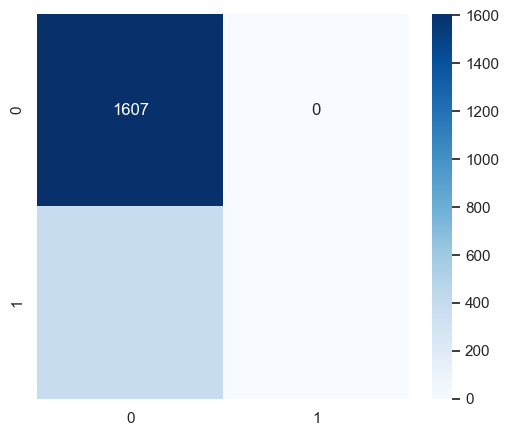

In [56]:
cm_SVM=confusion_matrix(y_test, y_pred_SVM)

plt.figure(figsize=(6,5))
sns.heatmap(cm_SVM, cmap='Blues', annot=True, fmt="g")
plt.show()